In [1]:
"""
This is a Python script that simulates the full flight of a rocket using the RocketPy library. It defines the rocket's physical characteristics, 
loads aerodynamic data, and sets up the environment for the simulation. The script also includes functions to analyze and visualize the rocket's flight performance.

Input files:
    RAS:
    - CD_power_off.csv: Contains the Mach against drag coefficient data for the rocket when the motor is off.
    - CD_power_on.csv: Contains the Mach against drag coefficient data for the rocket when the motor is on.
    - CP_position.csv: Contains the Mach agaist center of pressure (measured in inches from the tail) position data for the rocket during flight.
    Other sources:
    - Hex_airfoil.txt: Contains the coefficient of lift against unit of the curve (radians) for the rocket's fins.
    - thrust_curve.csv: Contains the time against thrust data for the rocket's motor.

Use OpenRocket to find CG values.

To install rocketpy:
    conda install -c conda-forge rocketpy
    
"""

from rocketpy import Environment, LiquidMotor, Rocket, Flight
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import datetime


Gravity Details

Acceleration of gravity at surface level:    9.7948 m/s²
Acceleration of gravity at  79.672 km (ASL): 9.5563 m/s²


Launch Site Details

Launch Date: 2026-09-04 12:00:00 UTC
Launch Site Latitude: 35.34712°
Launch Site Longitude: -117.80893°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 426495.69 W    3911838.99 N
Launch Site UTM zone: 11S
Launch Site Surface Elevation: 906.1 m


Atmospheric Model Details

Atmospheric Model Type: Forecast
Forecast Maximum Height: 79.672 km
Forecast Time Period: from 2026-08-27 00:00:00 to 2026-09-19 12:00:00 utc
Forecast Hour Interval: 3 hrs
Forecast Latitude Range: From 90.0° to -90.0°
Forecast Longitude Range: From 0.0° to 359.75°

Surface Atmospheric Conditions

Surface Wind Speed: 4.14 m/s
Surface Wind Direction: 233.44°
Surface Wind Heading: 53.44°
Surface Pressure: 907.45 hPa
Surface Temperature: 289.58 K
Surface Air Density: 1.092 kg/m³
Surface Speed of Sound: 341.14 m/s


Earth Model Details

Earth Radius at Launch s

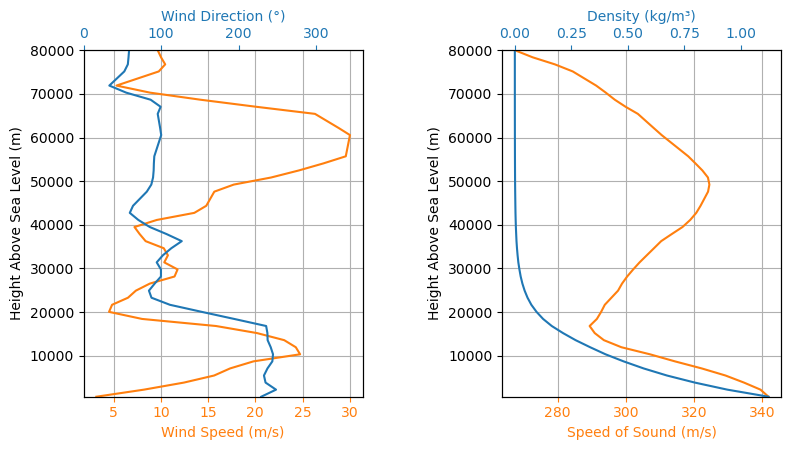

In [2]:
"""
Defining the launch environment for the rocket flight simulation. The environment is defined by its latitude, longitude, and elevation.
"""

env = Environment(latitude=35.3471229863, longitude=-117.808934230, elevation=628)

tomorrow = datetime.date.today() + datetime.timedelta(days=1)

env.set_date(
    (tomorrow.year, tomorrow.month, tomorrow.day, 12)
) # Hour given in UTC time

# setting the atmospehric model to be used
env.set_atmospheric_model(type="Forecast", file="GFS")

# get environment information
env.info()

In [3]:
"""
Imports thrust curve - CSV file of tuples (time, thrust).
"""

thrust_curve = "./full_flight_sim_inputs/thrust_curve.csv"
df = pd.read_csv(thrust_curve)
burn_time = df.iloc[:,0].astype(str).str.split().str[0].astype(float).max()
time_values = df.iloc[:,0].astype(str).str.split().str[0].astype(float)
thrust_values = df.iloc[:, 0].str.split().str[1].astype(float)

In [4]:
"""
Defining tank sizes and geometries, including probellant fluid properties.

Find density values online at environment temperatures. 
Errors will displayed if the tank volumes and fluid densities don't agree.
"""

from math import exp, sqrt
from rocketpy import Fluid, LiquidMotor, CylindricalTank, MassFlowRateBasedTank

# Define fluids
oxidizer_liq = Fluid(name="N2O_l", density=1220)
oxidizer_gas = Fluid(name="N2O_g", density=1.9277)
fuel_liq = Fluid(name="IPA_l", density=785.4)
fuel_gas = Fluid(name="IPA_g", density=31.8)

# Define fuel masses

fuel_mass = 6.3
oxidizer_mass = 16.7
propellant_mass = fuel_mass + oxidizer_mass

# Defining tank geometry

oxidizer_tank_length = 1.850
fuel_tank_length = 1.800

# Define Physical Dimensions

r_inner_nitrous = 0.070   # Inner radius of the Nitrous Tank
r_outer_nitrous = 0.076   # Outer radius of the Nitrous Tank
r_outer_fuel = 0.04445  # Outer radius of the Fuel Tank
r_inner_fuel = 0.0413   # Inner radius of the Fuel Tank

# RocketPy doesn't account for concentric tanks, so need to calculate the effective radius of the outer tank.
# Calculate Equivalent Radius for the Outer (Annular) Tank
# This ensures the fluid level drops at the correct physical rate
r_oxidizer_effective = sqrt(r_inner_nitrous**2 - (fuel_tank_length/oxidizer_tank_length)*r_outer_fuel**2)

# Define Geometry
# Use the EFFECTIVE radius for the outer tank
oxidizer_tank_shape = CylindricalTank(
    radius=r_oxidizer_effective, 
    height=oxidizer_tank_length, 
    spherical_caps=False
)

# Use the PHYSICAL radius for the inner tank
fuel_tank_shape = CylindricalTank(
    radius=r_inner_fuel, 
    height=fuel_tank_length, 
    spherical_caps=False
)

# Define tanks
oxidizer_tank = MassFlowRateBasedTank(
    name="oxidiser tank",
    geometry=oxidizer_tank_shape,
    flux_time=burn_time,
    initial_liquid_mass=oxidizer_mass,
    initial_gas_mass=0,
    liquid_mass_flow_rate_in=0,
    liquid_mass_flow_rate_out=1.976,
    gas_mass_flow_rate_in=0,
    gas_mass_flow_rate_out=0,
    liquid=oxidizer_liq,
    gas=oxidizer_gas,
)

fuel_tank = MassFlowRateBasedTank(
    name="fuel tank",
    geometry=fuel_tank_shape,
    flux_time=burn_time,
    initial_liquid_mass=fuel_mass,
    initial_gas_mass=0,
    liquid_mass_flow_rate_in=0,
    liquid_mass_flow_rate_out=0.782,
    gas_mass_flow_rate_in=0,
    gas_mass_flow_rate_out=0,
    liquid=fuel_liq,
    gas=fuel_gas,
)

/tmp/ipykernel_1486/1659627075.py:42: DeprecationWarning: The 'radius' argument in CylindricalTank is deprecated in v1.13.0 and will be removed in v2.0.0. Use 'radius_function' instead.
  oxidizer_tank_shape = CylindricalTank(
/tmp/ipykernel_1486/1659627075.py:49: DeprecationWarning: The 'radius' argument in CylindricalTank is deprecated in v1.13.0 and will be removed in v2.0.0. Use 'radius_function' instead.
  fuel_tank_shape = CylindricalTank(


In [5]:
"""
Defines the liquid motor of the rocket.

To find LiquidMotor values, in OpenRocket, set all components to zero mass except: fuel tanks, bulkheads, feed system, and engine.
"""

# Defining thrust matrix

thrust_data = pd.concat([time_values, thrust_values], axis=1).to_numpy()

liquid_motor = LiquidMotor(
    thrust_source=thrust_data,
    dry_mass=20.761,
    dry_inertia=(13,13,0.076), 
    nozzle_radius=0.051,
    center_of_dry_mass_position=1.113,
    nozzle_position=0,
    burn_time=burn_time,
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)

# Tank position measured at the centre of the tank

liquid_motor.add_tank(tank=oxidizer_tank, position=0.555+oxidizer_tank_length/2)
liquid_motor.add_tank(tank=fuel_tank, position=0.555+fuel_tank_length/2)

Nozzle Details
Nozzle Radius: 0.051 m

Motor Details
Total Burning Time: 8.055 s
Total Propellant Mass: 23.000 kg
Structural Mass Ratio: 0.474
Average Propellant Exhaust Velocity: 1233.273 m/s
Average Thrust: 3401.273 N
Maximum Thrust: 3922.1 N at 0.045 s after ignition.
Total Impulse: 27397.258 Ns



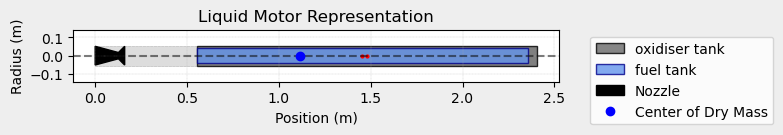

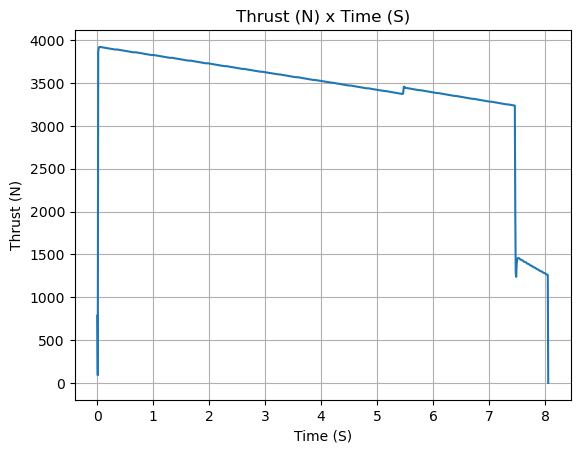

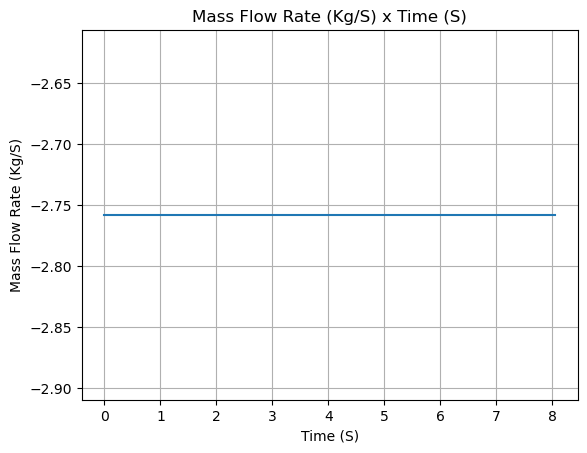

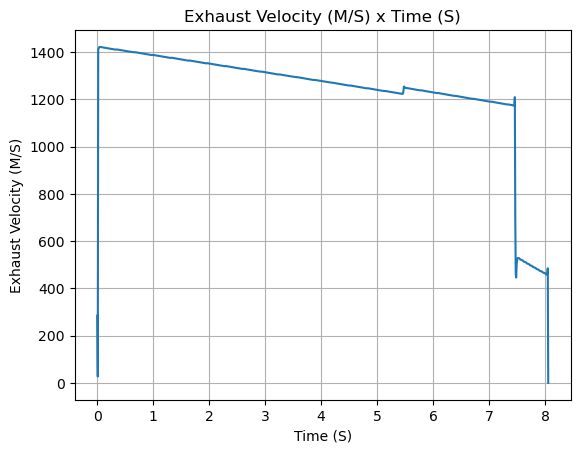

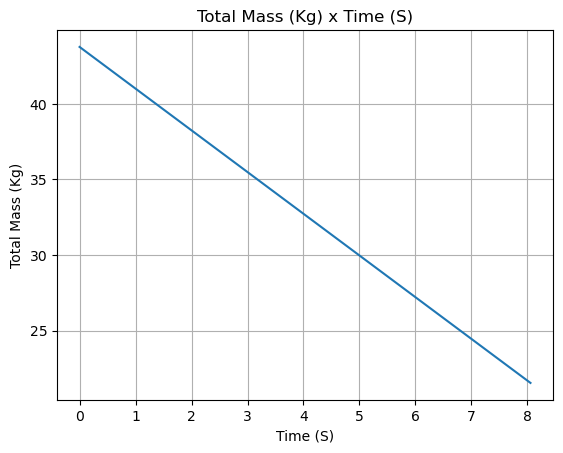

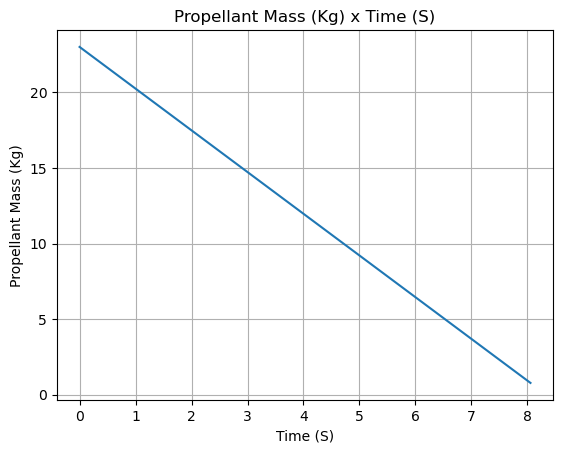

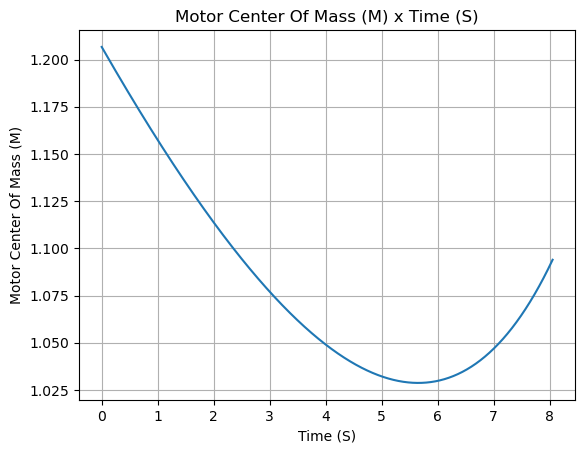

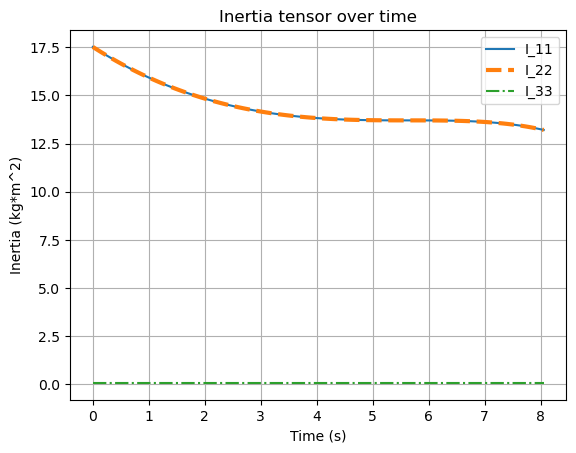

In [6]:
### Motor info

liquid_motor.all_info()

In [7]:
"""
Defining the liquid fuelled rocket, adding the motor, nosecone, fins, and tail.

Measurements of the rocket measured excluding the liquid_motor (tanks, bulkheads, feed system, and motor).
"""

import pandas as pd
import numpy as np
from rocketpy import Function, Rocket

power_off_array = pd.read_csv(
    "./full_flight_sim_inputs/CD_power_off.csv", 
    encoding="utf-8-sig"
).values

power_on_array = pd.read_csv(
    "./full_flight_sim_inputs/CD_power_on.csv", 
    encoding="utf-8-sig"
).values

power_off_func = Function(power_off_array, inputs="Mach", outputs="Drag Coefficient")
power_on_func = Function(power_on_array, inputs="Mach", outputs="Drag Coefficient")

liquid_rocket = Rocket(
    radius=0.076,
    mass=7.554,
    inertia=(9.36, 9.36, 0.055),
    power_off_drag=power_off_func,
    power_on_drag=power_on_func,
    center_of_mass_without_motor=1.844,
    coordinate_system_orientation="tail_to_nose",
)

# Adding the motor

liquid_rocket.add_motor(liquid_motor, position=0)

# Adding Aerodynamic Surfaces

nose_cone = liquid_rocket.add_nose(
    length=0.456, kind="ogive", position=2.900
)

fin_set = liquid_rocket.add_trapezoidal_fins(
    n=4,
    root_chord=0.380,
    tip_chord=0.070,
    span=0.167,
    position=0.532,
    cant_angle=0,
    sweep_length=0.371,
    airfoil=("./full_flight_sim_inputs/Hex_airfoil.txt", "radians")
)

tail = liquid_rocket.add_tail(
    top_radius=0.076, bottom_radius=0.051, length=0.152, position=0.152
)

In [8]:
"""
Calculates the CP position - converts the position in inches from the tail to meters from the nosecone. 

Converts it into a tuple of (Mach, CP position).
"""

import pandas as pd
from rocketpy import Function

# Load the raw OpenRocket data
df_cp = pd.read_csv("./full_flight_sim_inputs/CP_position.csv")

# Extract ONLY the ascent phase (from t=0 up to the maximum Mach number)
max_mach_idx = df_cp['Mach'].idxmax()
df_ascent = df_cp.iloc[:max_mach_idx+1].copy()

# Drop duplicate Mach values to ensure clean interpolation
df_ascent = df_ascent.drop_duplicates(subset=['Mach'])

# FILTER THE WOBBLES:
# Overwrite the AoA oscillations below Mach 0.8 with the true 0-AoA baseline (99.43 inches)
df_ascent.loc[df_ascent['Mach'] < 0.8, 'CP'] = 84.88

# Convert to meters from the nose (Rocket length = 3.262m)
cp_matrix = df_ascent[['Mach', 'CP']].to_numpy().copy()
cp_matrix[:, 1] = 2.900 - (cp_matrix[:, 1] * 0.0254) 

# Apply to the Rocket
liquid_rocket.cp_position = Function(
    cp_matrix,
    inputs="Mach Number",
    outputs="Center of Pressure Position (m)",
    interpolation="linear"
)

In [9]:
"""
Adding parachutes - find CD values from company website.
"""

main = liquid_rocket.add_parachute(
    name="Main",
    cd_s=5.79,
    trigger=800,
    sampling_rate=100,
    lag=1.5,
    noise=(0, 1 ,0),
)

drogue = liquid_rocket.add_parachute(
    name="Drogue",
    cd_s=0.9855,
    trigger="apogee",
    sampling_rate=100,
    lag=1.5,
    noise=(0, 1, 0),
)

In [10]:
"""
Adding rail buttons to the side of the rocket.
"""

rail_buttons = liquid_rocket.set_rail_buttons(
    upper_button_position=1.500,
    lower_button_position=0.500,
    angular_position=0
)


Inertia Details

Rocket Mass: 7.554 kg (without motor)
Rocket Dry Mass: 28.315 kg (with unloaded motor)
Rocket Loaded Mass: 51.315 kg
Rocket Structural Mass Ratio: 0.552
Rocket Inertia (with unloaded motor) 11: 25.320 kg*m2
Rocket Inertia (with unloaded motor) 22: 25.320 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.131 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.076 m
Rocket Frontal Area: 0.018146 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.536 m
Rocket Center of Dry Mass - Nozzle Exit: 1.308 m
Rocket Center of Dry Mass - Center of Propellant Mass: 0.017 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.008 m


Aerodynamics Lift Coefficient Derivatives

Nose Cone Lift Coefficient Derivative: 2.000/rad
Fins Lift Coefficient Derivative: 5.667/rad
Tail Lift Coefficient De

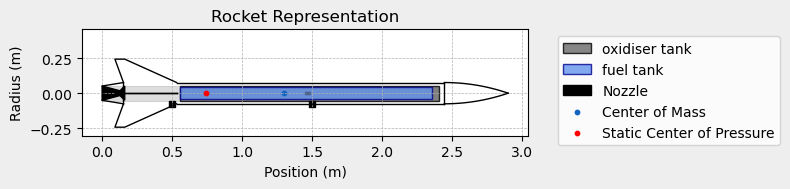


Mass Plots
----------------------------------------


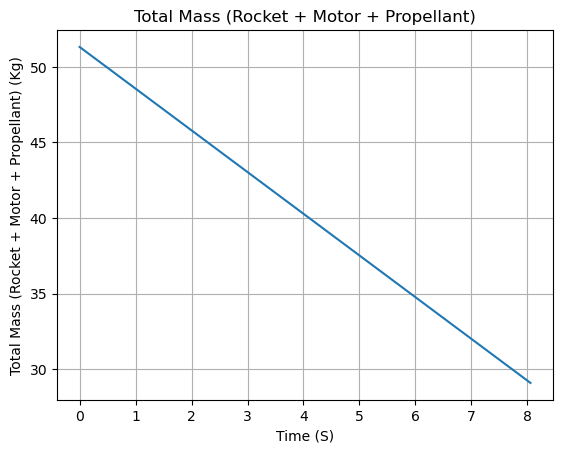

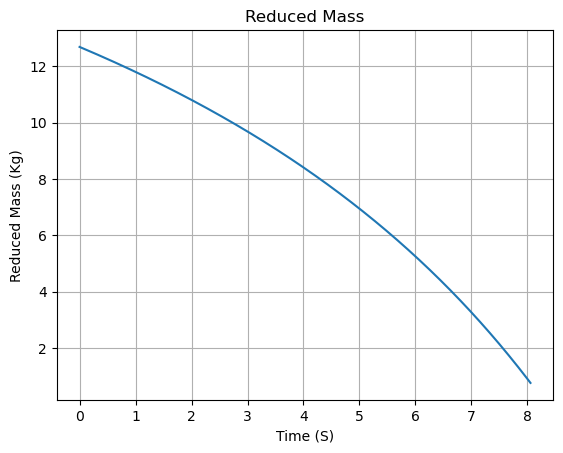


Aerodynamics Plots
----------------------------------------
Drag Plots
--------------------


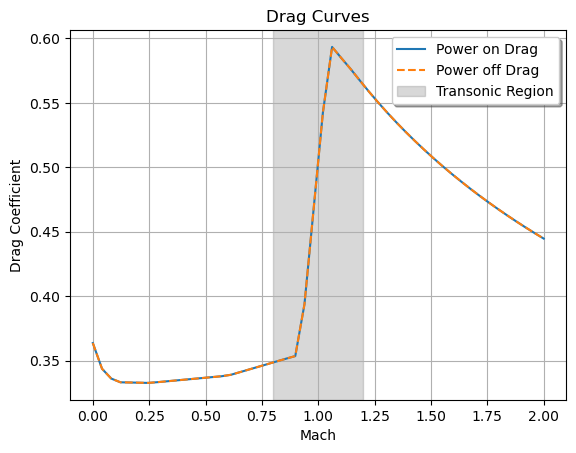


Stability Plots
--------------------


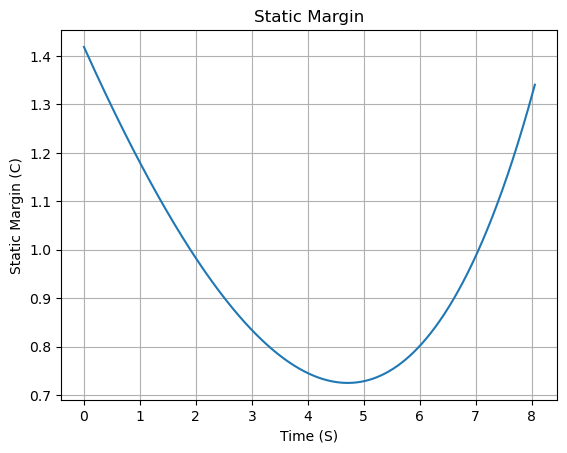

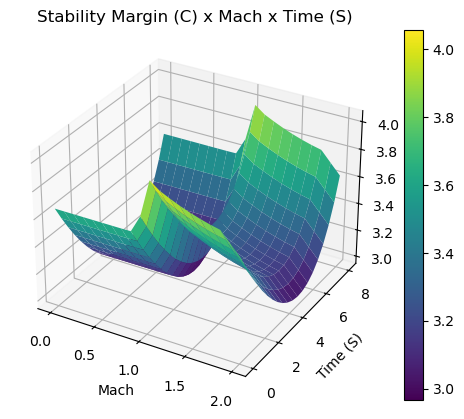


Thrust-to-Weight Plot
----------------------------------------


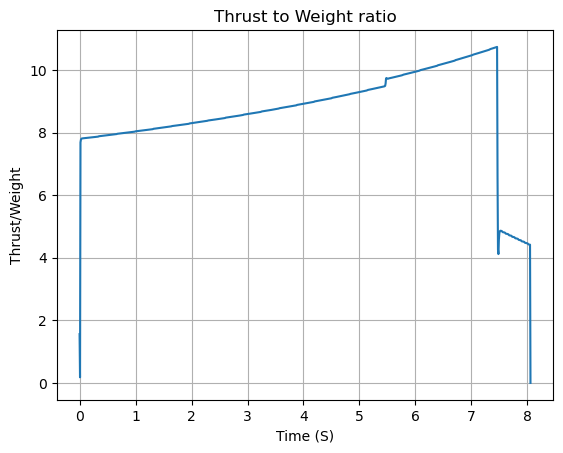

In [11]:
### Rocket info

liquid_rocket.all_info()

In [12]:
### Running a test flight

test_flight = Flight(
    rocket=liquid_rocket, environment=env, rail_length=15.24, inclination=90, heading=0
)


Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 906.12 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: 1.000 | e1: 0.000 | e2: 0.000 | e3: 0.000
Euler Angles - Spin φ : 180.00° | Nutation θ: 0.00° | Precession ψ: -180.00°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.00 rad/s
Initial Stability Margin: 3.661 c


Surface Wind Conditions

Frontal Surface Wind Speed: 2.44 m/s
Lateral Surface Wind Speed: -3.34 m/s


Launch Rail

Launch Rail Length: 15.24 m
Launch Rail Inclination: 90.00°
Launch Rail Heading: 0.00°


Rail Departure State

Rail Departure Time: 0.651 s
Rail Departure Velocity: 43.102 m/s
Rail Departure Stability Margin: 3.501 c
Rail Departure Angle of Attack: 5.581°
Rail Departure Thrust-Weight Ratio: 7.945
Rail Departure Reynolds Number: 3.995e+05


Burn out State

Burn out time: 8.055 s
Altitude at burn out: 3115.257 m (ASL) | 2209.134 m (AGL)
Rocket speed at burn out: 505.036 m/s
Freestream v

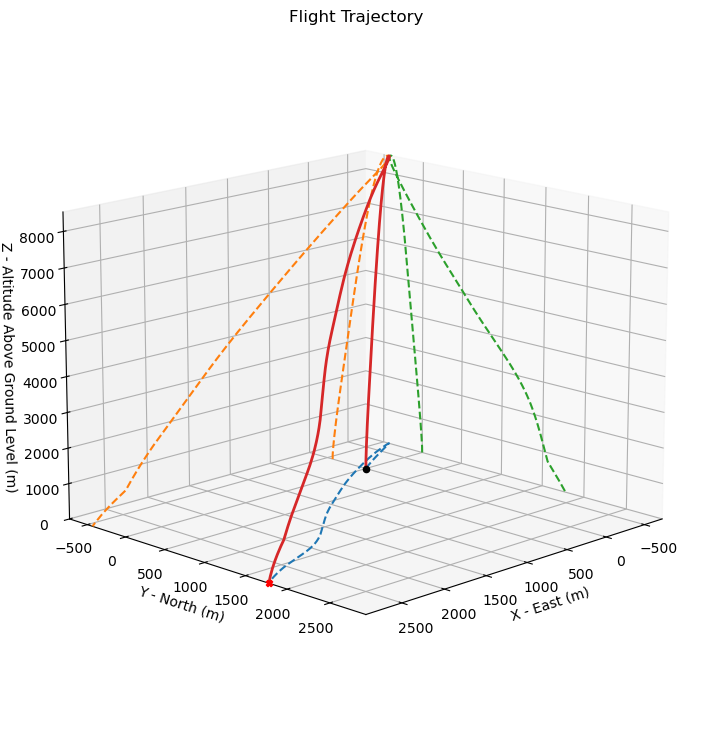



Trajectory Kinematic Plots



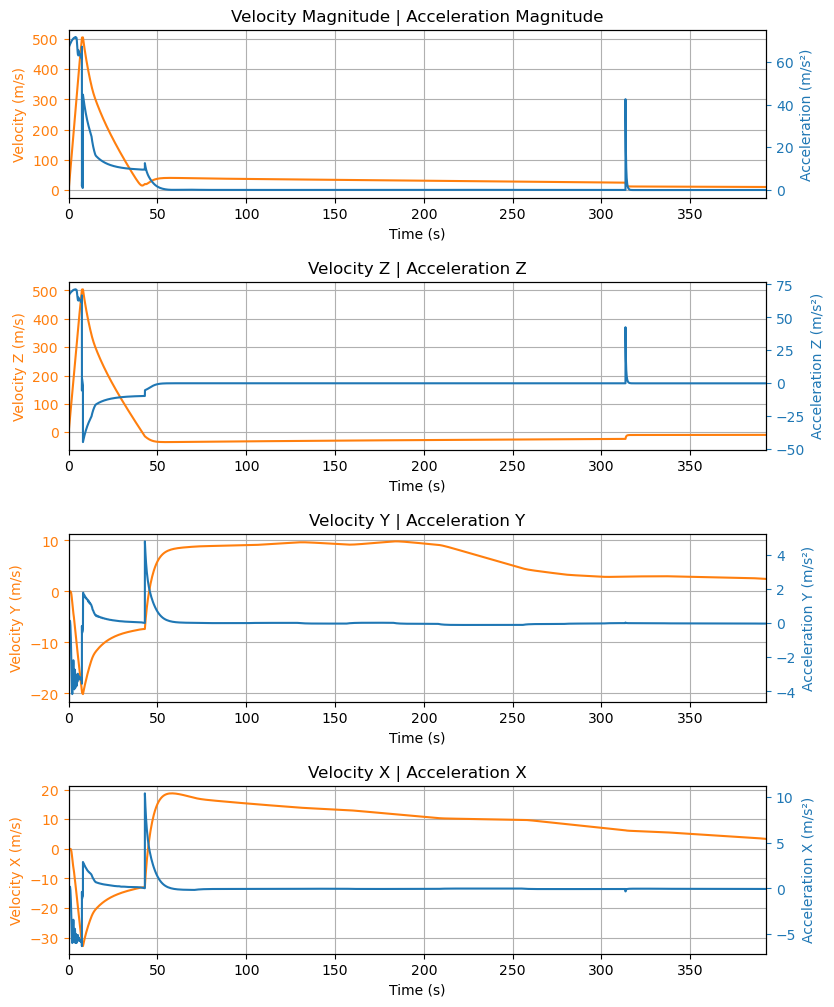



Angular Position Plots



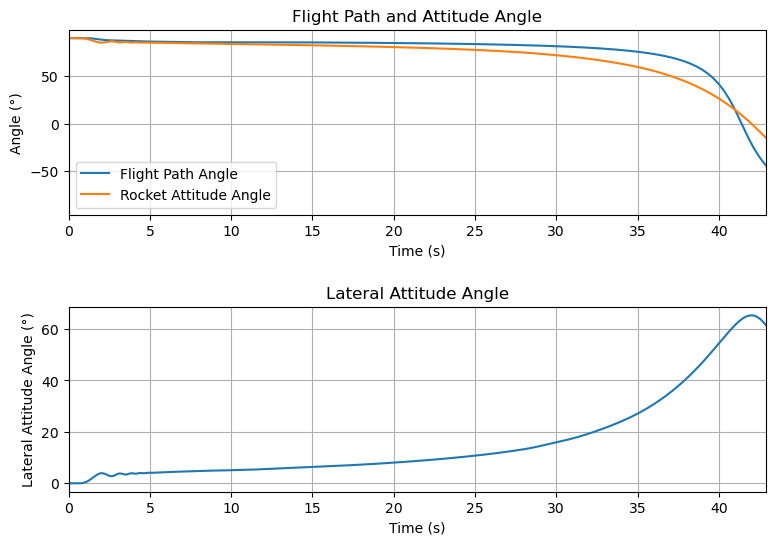



Path, Attitude and Lateral Attitude Angle Plots



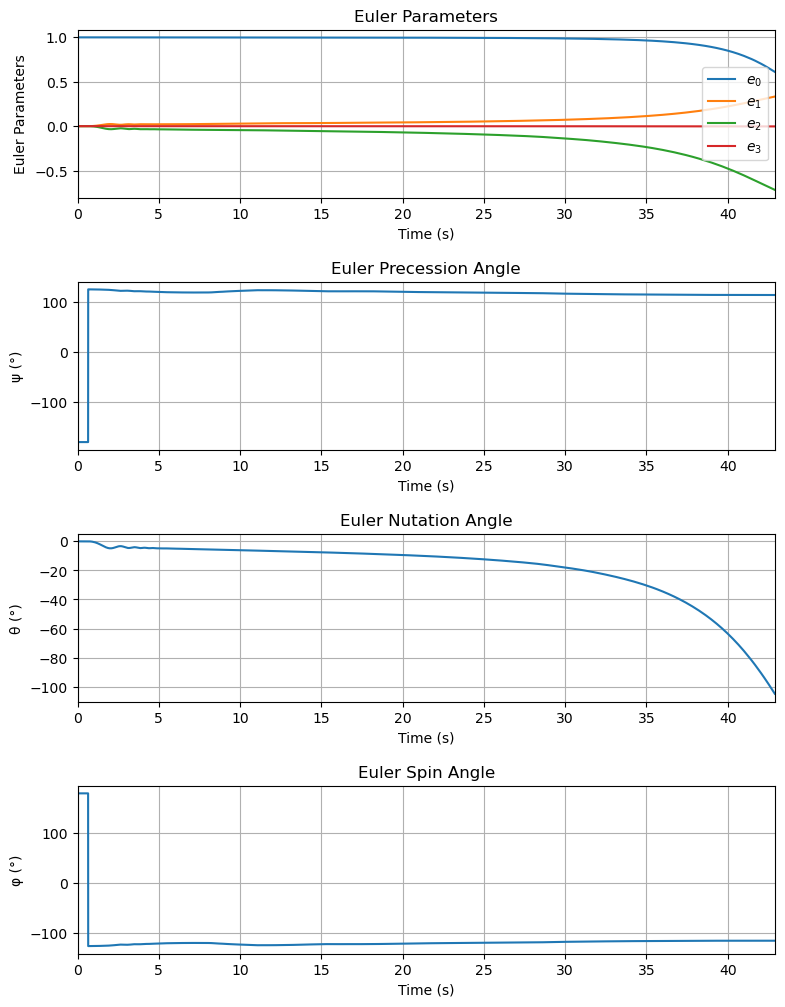



Trajectory Angular Velocity and Acceleration Plots



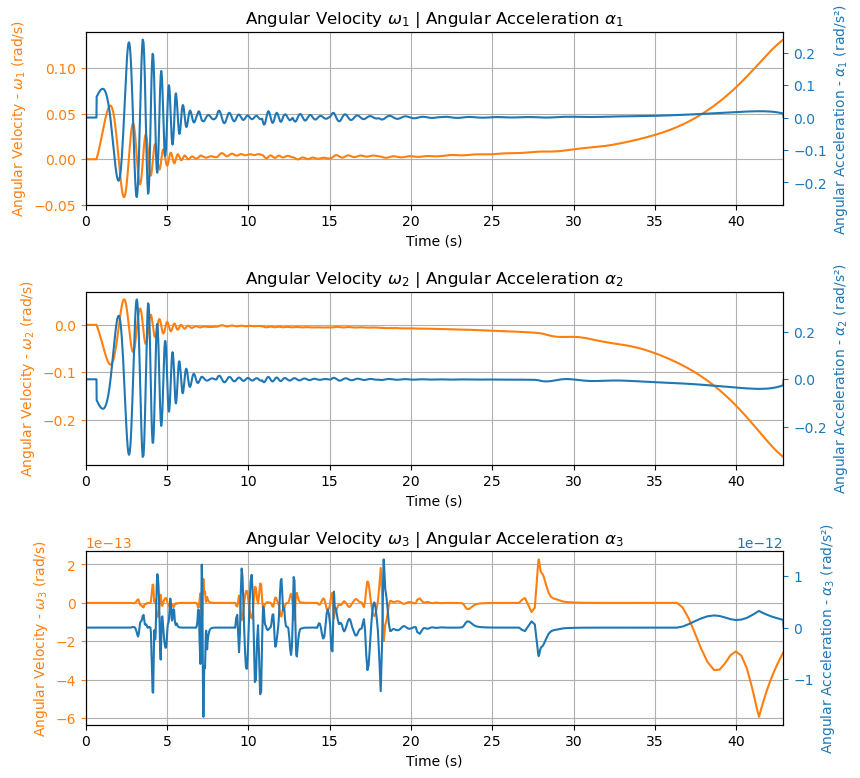



Aerodynamic Forces Plots



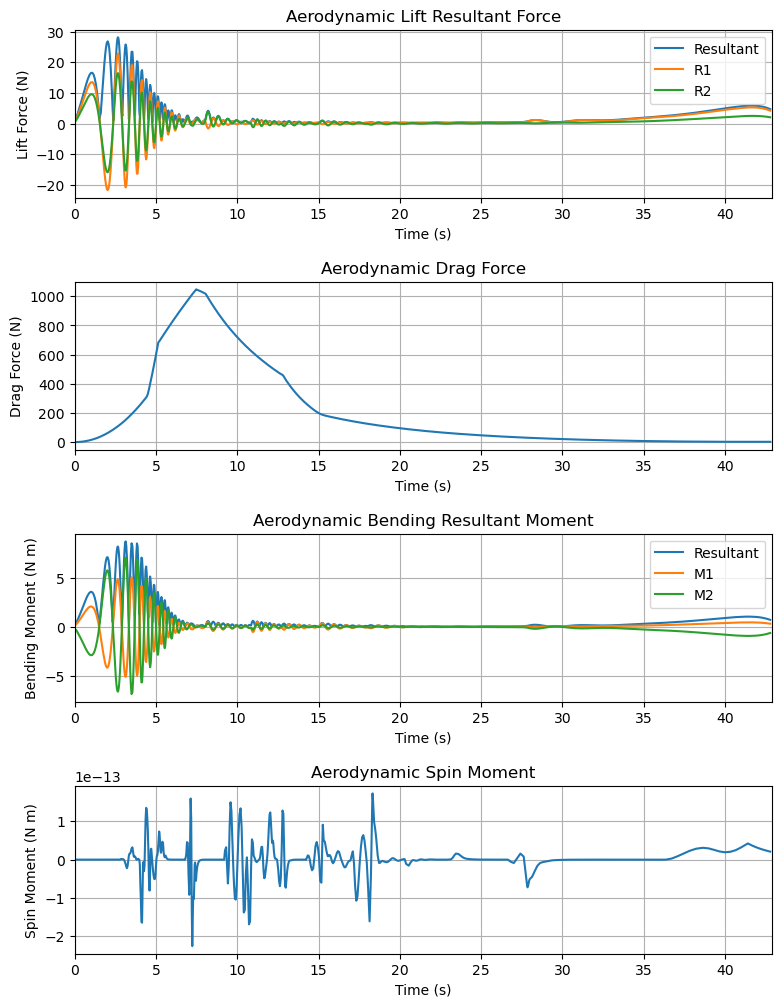

Rail button height not defined. Skipping bending moment plots.




Rail Buttons Bending Moments Plots



Rail Buttons Forces Plots



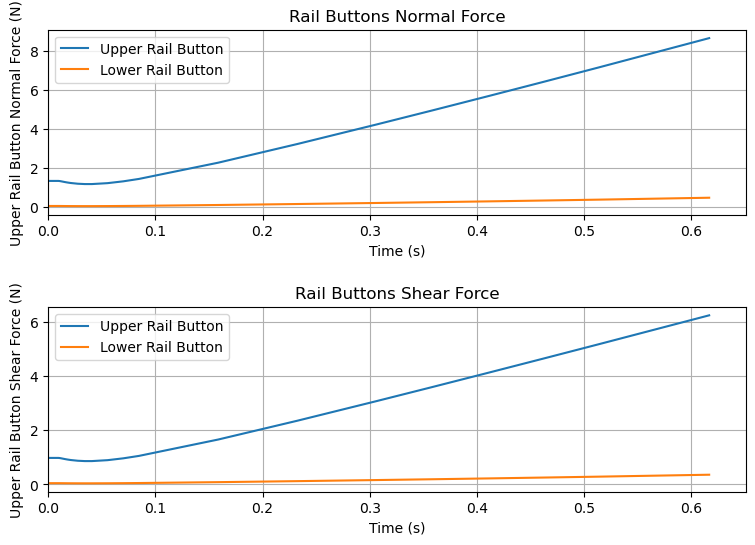



Trajectory Energy Plots



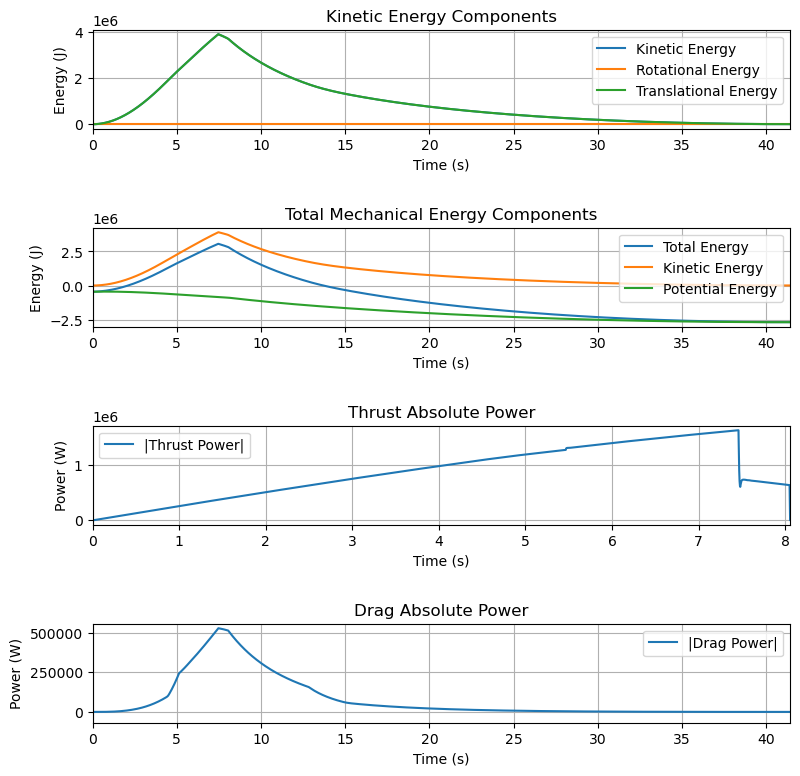



Trajectory Fluid Mechanics Plots



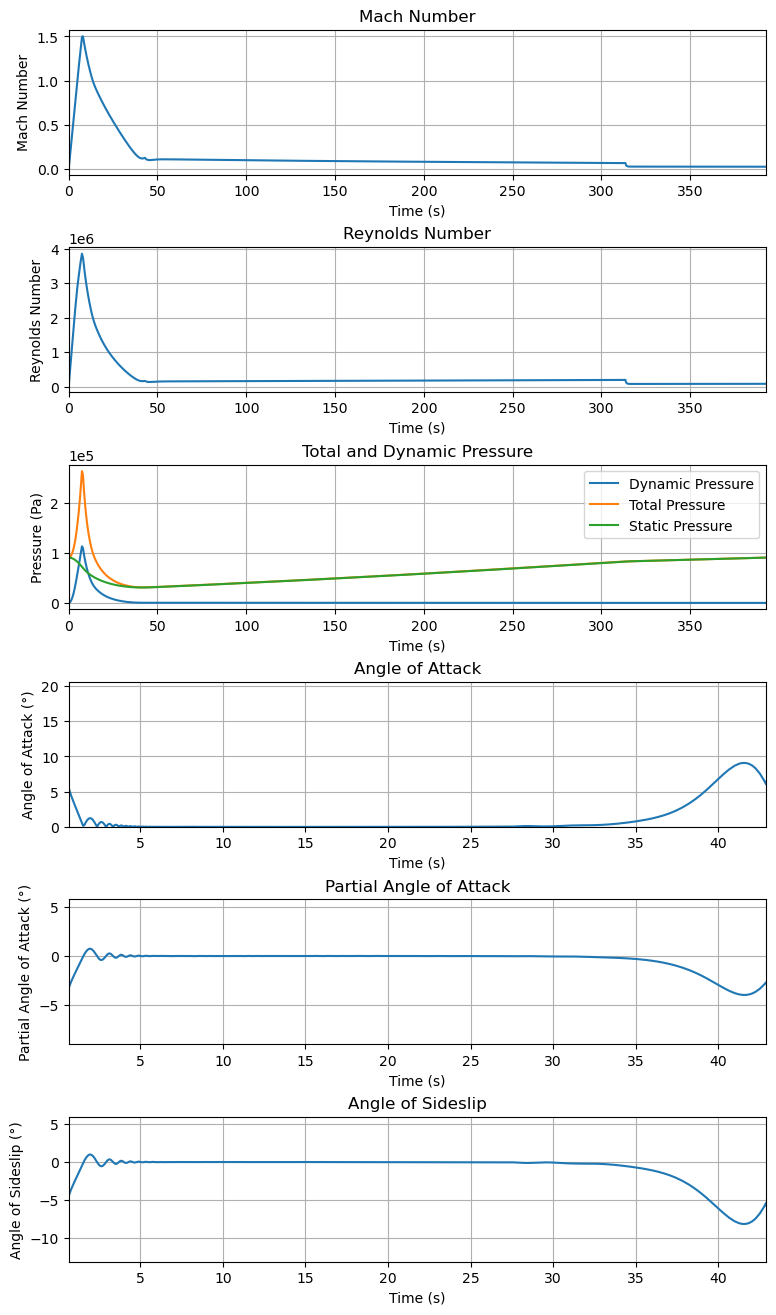



Trajectory Stability and Control Plots



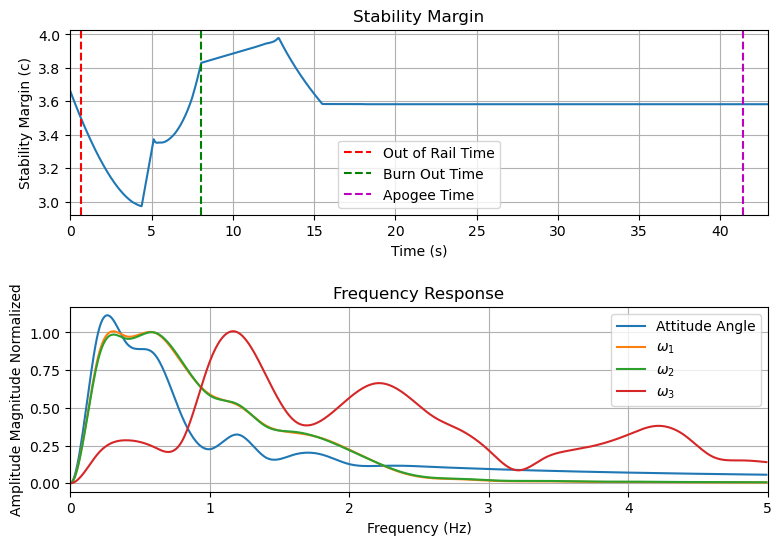



Rocket and Parachute Pressure Plots



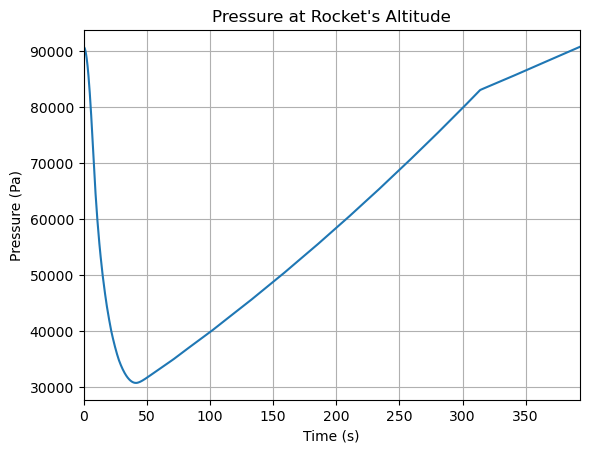

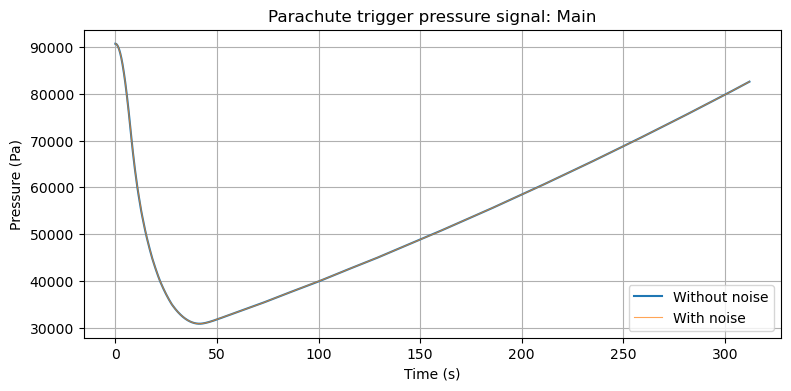

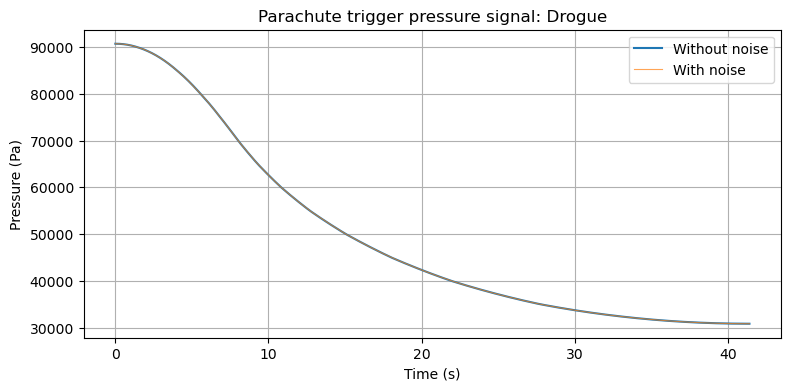

In [13]:
### Test Flight Information
# creates plots of trajectory and gives major information on the test flight

test_flight.all_info()

In [14]:
test_flight.prints.maximum_values()


Maximum Values

Maximum Speed: 505.222 m/s at 7.91 s
Maximum Mach Number: 1.501 Mach at 8.05 s
Maximum Reynolds Number: 3.852e+06 at 7.47 s
Maximum Dynamic Pressure: 1.133e+05 Pa at 7.47 s
Maximum Acceleration During Motor Burn: 71.512 m/s² at 3.91 s
Maximum Gs During Motor Burn: 7.292 g at 3.91 s
Maximum Acceleration After Motor Burn: 44.686 m/s² at 8.06 s
Maximum Gs After Motor Burn: 4.557 Gs at 8.06 s
Maximum Stability Margin: 3.978 c at 12.78 s
Maximum Upper Rail Button Normal Force: 9.141 N
Maximum Upper Rail Button Shear Force: 6.602 N
Maximum Lower Rail Button Normal Force: 0.519 N
Maximum Lower Rail Button Shear Force: 0.385 N


In [15]:
"""
Visualising the Trajectory in Google Earth
"""

from rocketpy.simulation import FlightDataExporter

FlightDataExporter(test_flight).export_kml(
    file_name="trajectory.kml",
    extrude=True,
    altitude_mode="relative_to_ground"
)

Running Custom Monte Carlo (50 flights) with hardware & wind variance...


<>:136: SyntaxWarning: invalid escape sequence '\s'
<>:136: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1486/159093066.py:136: SyntaxWarning: invalid escape sequence '\s'
  label=f'{sigma}$\sigma$ Confidence'


Completed 10/50 simulations...
Completed 20/50 simulations...
Completed 30/50 simulations...
Completed 40/50 simulations...
Completed 50/50 simulations...

--- Monte Carlo Statistical Summary ---
                        mean          std          min           max
impact_x         3089.813486  1326.573298  -713.421913   6156.746756
impact_y         2375.266128  1000.419564   490.029725   4714.587029
apogee           9106.247753   334.584983  8365.601577  10049.412745
apogee_x          -67.527224   415.244543 -1163.004167    835.063266
apogee_y            1.076802    13.184746   -40.299105     23.445403
out_of_rail_vel    45.415811     0.055864    45.262282     45.529729
max_velocity      502.616791     7.313271   487.695861    525.042683
max_mach            1.486793     0.022912     1.439485      1.554672
flight_time       392.720173    20.021311   355.022807    450.511469


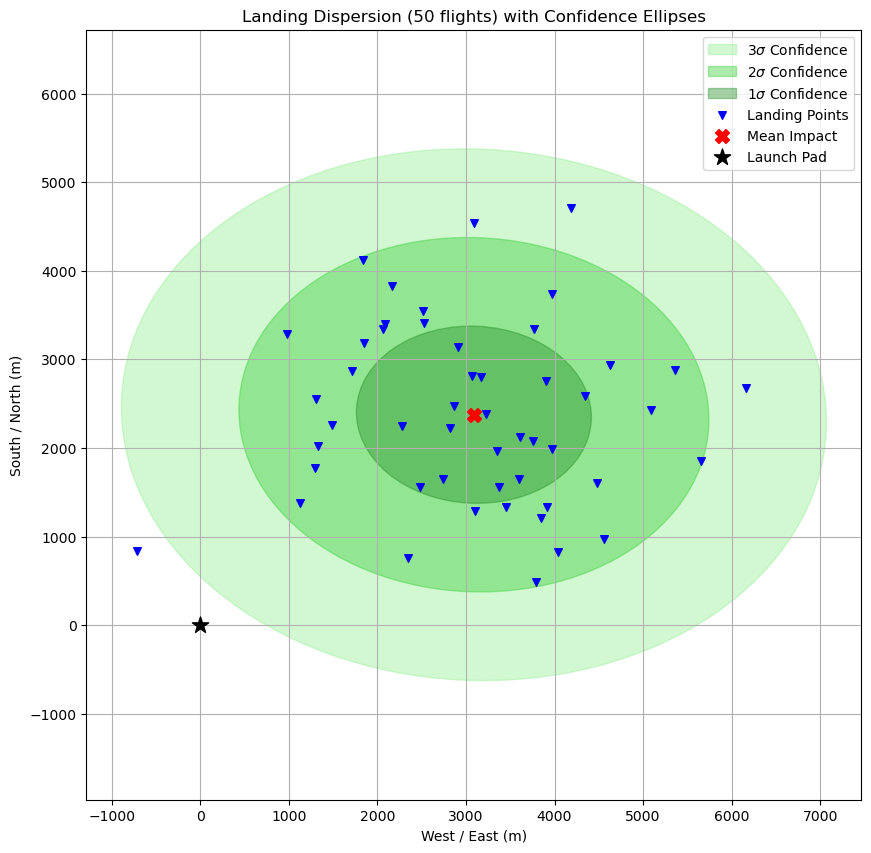

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from rocketpy import Flight, Environment, LiquidMotor
from rocketpy.stochastic import StochasticRocket, StochasticParachute

# 1. Randomize the Rocket hardware and aerodynamics
stoch_rocket = StochasticRocket(
    rocket=liquid_rocket,      
    mass=(7.554, 0.1),         
    inertia_11=(25.320, 0.5),  
    inertia_22=(25.320, 0.5),  
    inertia_33=(0.131, 0.01),  
    power_off_drag_factor=(1.0, 0.1), 
    power_on_drag_factor=(1.0, 0.1),
    center_of_mass_without_motor=(1.844, 0.05) 
)

# 2. EQUIP LIQUIDMOTOR WITH STOCHASTIC METHODS (The Patch)
def _mock_create_object(self): return self
def _mock_get_obj(self): return self
def _mock_get_last_rnd_dict(self): return {"motor_type": "Deterministic LiquidMotor"}
def _mock_dict(self): return {"motor_type": "Deterministic LiquidMotor"}

if not hasattr(LiquidMotor, 'create_object'): LiquidMotor.create_object = _mock_create_object
if not hasattr(LiquidMotor, 'obj'): LiquidMotor.obj = property(_mock_get_obj)
if not hasattr(LiquidMotor, 'last_rnd_dict'): LiquidMotor.last_rnd_dict = property(_mock_get_last_rnd_dict)
if not hasattr(LiquidMotor, 'dict'): LiquidMotor.dict = _mock_dict

stoch_rocket.add_motor(liquid_motor, position=(0, 0))            

# 3. EXPLICITLY ADD PARACHUTE VARIANCE
stoch_rocket.parachutes.clear() 

stoch_main = StochasticParachute(
    parachute=main, 
    cd_s=(5.79, 0.5)     # Nominal 5.79, plus +/- 0.5m^2 std dev[cite: 2]
)
stoch_drogue = StochasticParachute(
    parachute=drogue, 
    cd_s=(0.9855, 0.1)   # Nominal 0.9855, plus +/- 0.1m^2 std dev[cite: 2]
)

stoch_rocket.add_parachute(stoch_main)
stoch_rocket.add_parachute(stoch_drogue)

# 4. CUSTOM MONTE CARLO LOOP WITH COMPREHENSIVE TRACKING
N_SIMS = 50

# Dictionary to track all flight variables
results = {
    'impact_x': [], 'impact_y': [], 
    'apogee': [], 'apogee_x': [], 'apogee_y': [],
    'out_of_rail_vel': [], 'max_velocity': [], 
    'max_mach': [], 'flight_time': []
}

print(f"Running Custom Monte Carlo ({N_SIMS} flights) with hardware & wind variance...")

def make_wind_u(shift): 
    return lambda h: env.wind_velocity_x(h) + shift
def make_wind_v(shift): 
    return lambda h: env.wind_velocity_y(h) + shift

for i in range(N_SIMS):
    # Apply a random Gaussian shift to the wind (+/- 3 m/s variance)
    shift_u = np.random.normal(0, 3)
    shift_v = np.random.normal(0, 3)
    
    # Build local environment using the existing base `env` pressure/temp 
    temp_env = Environment(latitude=35.34712, longitude=-117.80893, elevation=628) 
    temp_env.set_atmospheric_model(
        type="custom_atmosphere",
        pressure=env.pressure,
        temperature=env.temperature,
        wind_u=make_wind_u(shift_u),
        wind_v=make_wind_v(shift_v)
    )
    
    temp_rocket = stoch_rocket.create_object()
    
    temp_flight = Flight(
        rocket=temp_rocket,
        environment=temp_env,
        rail_length=15.24,
        inclination=np.random.normal(90, 1.5),
        heading=np.random.normal(90, 2),
        max_time=3600,
        verbose=False
    )
    
    # Track all the important flight variables
    results['impact_x'].append(temp_flight.x_impact)
    results['impact_y'].append(temp_flight.y_impact)
    results['apogee'].append(temp_flight.apogee)
    results['apogee_x'].append(temp_flight.apogee_x)
    results['apogee_y'].append(temp_flight.apogee_y)
    results['out_of_rail_vel'].append(temp_flight.out_of_rail_velocity)
    results['max_velocity'].append(temp_flight.max_speed)
    results['max_mach'].append(temp_flight.max_mach_number)
    results['flight_time'].append(temp_flight.t_final)
    
    if (i + 1) % 10 == 0:
        print(f"Completed {i+1}/{N_SIMS} simulations...")

# 5. PRINT STATISTICAL SUMMARY
df_results = pd.DataFrame(results)
print("\n--- Monte Carlo Statistical Summary ---")
# Print the Mean, Standard Deviation, Min, and Max for all tracked variables
print(df_results.describe().T[['mean', 'std', 'min', 'max']])

# 6. CALCULATE COVARIANCE ELLIPSES
impact_x = df_results['impact_x']
impact_y = df_results['impact_y']

mean_x, mean_y = np.mean(impact_x), np.mean(impact_y)
cov_matrix = np.cov(impact_x, impact_y)
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))

# 7. PLOT DISPERSION MAP WITH ELLIPSES
fig, ax = plt.subplots(figsize=(10, 10))

# Draw the 3-sigma, 2-sigma, and 1-sigma ellipses (in reverse order so they overlap properly)
colors = {3: 'lightgreen', 2: 'limegreen', 1: 'forestgreen'}
for sigma in [3, 2, 1]:
    ell = Ellipse(
        xy=(mean_x, mean_y),
        width=2 * sigma * np.sqrt(eigenvalues[0]),
        height=2 * sigma * np.sqrt(eigenvalues[1]),
        angle=angle,
        edgecolor=colors[sigma],
        facecolor=colors[sigma],
        alpha=0.4,
        label=f'{sigma}$\sigma$ Confidence'
    )
    ax.add_patch(ell)

# Draw the actual landing points and launch pad
ax.scatter(impact_x, impact_y, color='blue', marker='v', s=30, label='Landing Points', zorder=5)
ax.scatter(mean_x, mean_y, color='red', marker='X', s=100, label='Mean Impact', zorder=6)
ax.scatter(0, 0, color='black', marker='*', s=150, label='Launch Pad', zorder=6)

ax.set_xlabel("West / East (m)")
ax.set_ylabel("South / North (m)")
ax.set_title(f"Landing Dispersion ({N_SIMS} flights) with Confidence Ellipses")
ax.legend()
ax.grid(True)
ax.axis('equal') 
plt.savefig("landing_dispersion_with_ellipses.png", dpi=300)
plt.show()